# VSL400 — Notebook 21 | Video mẫu ký hiệu đơn để thử webcam

**Chức năng:** lựa chọn những ký hiệu **đã từng được nhận diện chính xác** bởi checkpoint `TCN-Transformer-CTC`, seed **20260827**, trong dữ liệu ký hiệu đơn thuộc Validation và Test; hiển thị **video người ký thực tế ngay trong cell**, thống kê **FPS / thời lượng của từng video**, và đưa ra hướng dẫn thực hiện lại trên webcam.

**Giới hạn bắt buộc:** không có ký hiệu nào được bảo đảm *chắc chắn nhận diện đúng* với người mới/camera mới. Các mẫu được tuyển chọn từ đầu ra đã biết, phục vụ **demo và kiểm thử vận hành**, **không** được xem là phép đánh giá khoa học mới hoặc thay WER chính thức. Kết quả Test được sử dụng *sau khi checkpoint đã khóa* chỉ để tìm video minh họa, không chọn lại mô hình.

**Kaggle:** Accelerator **None / CPU**, Internet **Off**. Trong **Add Input**, gắn dataset Kaggle **`nguyenanfms/vsl-vietnamese-sign-language-v2`**, gồm thư mục `raw/raw/VSL400/.../front_view/*.mp4`. Không cần tải lại hoặc huấn luyện mô hình. Để chạy kiểm thử checkpoint trực tiếp trên keypoints, có thể gắn thêm Saved Versions **`VSL400_SHARED_KEYPOINTS_V1`** và **`VSL400_11_MULTISEED_TCN_TRANSFORMER`** (tùy chọn).

**Nguồn chứng cứ của danh sách có sẵn trong notebook:** kết quả Validation seed 20260827; Final Test seed 20260827; bộ recipe QA và thống kê chất lượng video. Mẫu được liệt kê bằng **video_id + signer_id + gloss gốc**, không phải video tự tạo. Các video có thể xem trực tiếp nhờ `IPython.display.Video`.

In [1]:
# 01 — Thư viện và tùy chọn cho người dùng
from pathlib import Path
from io import StringIO
from IPython.display import display, Video, Markdown, HTML
import math, re, json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# THAY DANH SÁCH DƯỚI ĐÂY ĐỂ CHỌN GLOSS MUỐN XEM.
TARGET_GLOSSES = ['Con bò', 'Trường học', 'Mưa', 'Bố', 'Em', 'Giúp đỡ', 'Thời tiết', 'Nhà trọ']
# Số người ký / video cho mỗi gloss cần xem. Giới hạn để notebook không quá nặng.
VIDEOS_PER_GLOSS = 1
PREFER_SPLIT = 'test'       # 'test' hoặc 'val'; là nguồn video hiển thị, không phải chia dữ liệu mới
SHOW_STORYBOARD = True      # 5 ảnh khung hình giúp quan sát chuyển động
SHOW_INLINE_VIDEO = True    # phát trực tiếp trong cell
PLAY_WIDTH = 440

OUTPUT_DIR = Path('/kaggle/working/VSL400_SIGN_DEMO_REFERENCE')
OUTPUT_DIR.mkdir(exist_ok=True,parents=True)
print('Số gloss yêu cầu:',len(TARGET_GLOSSES))

Số gloss yêu cầu: 8


In [2]:
# 02 — Danh sách kiểm chứng từ kết quả thực nghiệm; không cần tải thêm CSV riêng
CATALOG_CSV = '''
gloss,split,video_id,signer_id,label_id,sequence_id,clip_frames_qa,start_hold_frames,end_hold_frames,expected_frames,valid_left,valid_right,motion_energy,exact_in_recorded_recipe,val_one_gloss_correct,val_one_gloss_total,test_one_gloss_correct,test_one_gloss_total,test_alignment_f1,test_reference_support
Trường học,val,002624,004,332,val_004900,56,2,4,62,0.82143,0.85714,0.12477,True,4,4,6,6,0.875,35
Trường học,val,014264,019,332,val_001073,61,3,2,66,0.85246,0.78689,0.15051,True,4,4,6,6,0.875,35
Trường học,test,010504,014,332,test_001172,77,3,5,85,0.88312,0.85714,0.09969,True,4,4,6,6,0.875,35
Trường học,test,000073,001,332,test_002638,64,3,4,71,0.875,0.70312,0.20103,True,4,4,6,6,0.875,35
Nhân viên văn phòng,val,023541,027,230,val_000999,99,3,5,107,0.78788,0.88889,0.08634,True,6,7,4,4,0.76543,35
Nhân viên văn phòng,val,002921,004,230,val_001093,79,2,3,84,0.79747,0.72152,0.12648,True,6,7,4,4,0.76543,35
Nhân viên văn phòng,test,000359,001,230,test_002220,71,4,3,78,0.90141,0.83099,0.09392,True,6,7,4,4,0.76543,35
Nhân viên văn phòng,test,010817,014,230,test_001656,77,3,3,83,0.76623,0.81818,0.13113,True,6,7,4,4,0.76543,35
Không quen,val,003341,004,153,val_001411,63,5,5,73,1.0,0.79365,0.11536,True,6,6,4,5,0.7234,47
Không quen,val,014940,019,153,val_002476,68,4,3,75,1.0,0.76471,0.12533,True,6,6,4,5,0.7234,47
Không quen,test,024640,028,153,test_001394,74,4,2,80,1.0,0.86486,0.04348,True,6,6,4,5,0.7234,47
Không quen,test,000785,001,153,test_003324,66,3,4,73,1.0,0.84848,0.04658,True,6,6,4,5,0.7234,47
Xem,val,003295,004,362,val_000761,66,2,2,70,1.0,0.81818,0.10853,True,4,4,6,7,0.68687,45
Xem,val,023917,027,362,val_000331,58,3,2,63,1.0,0.58621,0.1116,True,4,4,6,7,0.68687,45
Xem,test,000739,001,362,test_000948,60,2,3,65,1.0,0.85,0.07509,True,4,4,6,7,0.68687,45
Xem,test,024617,028,362,test_001866,56,3,3,62,1.0,0.71429,0.17225,True,4,4,6,7,0.68687,45
Con bò,val,023882,027,56,val_004418,74,2,2,78,0.87838,0.86486,0.13231,True,5,5,4,4,0.95652,48
Con bò,val,014819,019,56,val_000675,65,2,5,72,0.8,0.76923,0.21394,True,5,5,4,4,0.95652,48
Con bò,test,024582,028,56,test_002864,60,5,4,69,0.8,0.81667,0.16511,True,5,5,4,4,0.95652,48
Con bò,test,011148,014,56,test_000842,64,3,5,72,0.875,0.79688,0.27328,True,5,5,4,4,0.95652,48
Vâng lời,val,014684,019,352,val_002167,65,5,4,74,0.87692,0.86154,0.168,True,4,4,5,5,0.91139,42
Vâng lời,val,023817,027,352,val_000057,58,2,2,62,0.72414,0.81034,0.12286,True,4,4,5,5,0.91139,42
Vâng lời,test,000522,001,352,test_001738,52,3,3,58,0.84615,0.69231,0.17875,True,4,4,5,5,0.91139,42
Vâng lời,test,011000,014,352,test_004586,58,4,4,66,0.84483,0.53448,0.24134,True,4,4,5,5,0.91139,42
Nhà trọ,val,002647,004,228,val_002941,73,4,2,79,0.84932,0.87671,0.1442,True,4,4,4,4,0.8913,47
Nhà trọ,val,014287,019,228,val_003131,70,2,5,77,0.84286,0.84286,0.12052,True,4,4,4,4,0.8913,47
Nhà trọ,test,000096,001,228,test_001928,71,2,5,78,0.85915,0.80282,0.19467,True,4,4,4,4,0.8913,47
Nhà trọ,test,010528,014,228,test_002896,75,4,4,83,0.70667,0.86667,0.12806,True,4,4,4,4,0.8913,47
Thời tiết,val,023422,027,317,val_000996,78,5,5,88,1.0,0.87179,0.1134,True,5,5,4,4,0.80899,44
Thời tiết,val,002654,004,317,val_004863,70,5,5,80,1.0,0.82857,0.04853,True,5,5,4,4,0.80899,44
Thời tiết,test,010532,014,317,test_003082,70,5,2,77,1.0,0.8,0.13617,True,5,5,4,4,0.80899,44
Thời tiết,test,024222,028,317,test_001697,92,5,2,99,1.0,0.78261,0.13014,True,5,5,4,4,0.80899,44
Mưa,val,002672,004,197,val_000403,60,5,2,67,0.81667,0.88333,0.19106,True,5,5,3,3,0.90667,34
Mưa,val,014308,019,197,val_001099,57,3,3,63,0.84211,0.68421,0.25448,True,5,5,3,3,0.90667,34
Mưa,test,010556,014,197,test_003794,66,2,5,73,0.80303,0.84848,0.20231,True,5,5,3,3,0.90667,34
Mưa,test,024230,028,197,test_004628,69,2,4,75,0.7971,0.7971,0.19706,True,5,5,3,3,0.90667,34
Tỉnh,val,023406,027,344,val_003336,63,3,5,71,0.80952,0.68254,0.11738,True,4,4,4,4,0.56566,40
Tỉnh,val,002617,004,344,val_001455,60,5,4,69,0.4,0.9,0.11721,True,4,4,4,4,0.56566,40
Tỉnh,test,010498,014,344,test_002795,63,5,3,71,0.77778,0.87302,0.11477,True,4,4,4,4,0.56566,40
Tỉnh,test,024206,028,344,test_001764,72,3,5,80,0.72222,0.91667,0.07483,True,4,4,4,4,0.56566,40
Học sinh,val,023650,027,141,val_003688,70,4,3,77,1.0,0.68571,0.04809,True,3,3,5,5,0.86154,34
Học sinh,val,002939,004,141,val_003028,67,4,2,73,1.0,0.65672,0.04095,True,3,3,5,5,0.86154,34
Học sinh,test,010841,014,141,test_000654,62,5,3,70,1.0,0.58065,0.16389,True,3,3,5,5,0.86154,34
Học sinh,test,024350,028,141,test_002126,52,4,3,59,0.65385,0.15385,0.28579,True,3,3,5,5,0.86154,34
Con dê,val,014821,019,58,val_004854,66,5,5,76,0.90909,0.83333,0.1802,True,6,6,2,2,0.85714,28
Con dê,val,003221,004,58,val_000048,73,3,5,81,0.82192,0.87671,0.11754,True,6,6,2,2,0.85714,28
Con dê,test,011149,014,58,test_001589,73,3,2,78,0.79452,0.89041,0.12771,True,6,6,2,2,0.85714,28
Con dê,test,024583,028,58,test_003339,59,5,4,68,0.91525,0.74576,0.1246,True,6,6,2,2,0.85714,28
Giúp đỡ,val,003066,004,116,val_004867,63,3,5,71,0.84127,0.8254,0.12215,True,5,5,3,3,0.74468,54
Giúp đỡ,val,023710,027,116,val_002909,67,5,3,75,0.9403,0.8209,0.09385,True,5,5,3,3,0.74468,54
Giúp đỡ,test,024410,028,116,test_004568,69,4,2,75,0.94203,0.92754,0.07306,True,5,5,3,3,0.74468,54
Giúp đỡ,test,010983,014,116,test_001641,69,3,2,74,0.81159,0.86957,0.17165,True,5,5,3,3,0.74468,54
Bố,val,023905,027,33,val_003266,63,4,5,72,1.0,0.88889,0.0343,True,4,4,3,3,0.84091,38
Bố,val,014866,019,33,val_000212,60,2,5,67,1.0,0.83333,0.03184,True,4,4,3,3,0.84091,38
Bố,test,000715,001,33,test_001755,47,2,4,53,1.0,0.76596,0.09888,True,4,4,3,3,0.84091,38
Bố,test,011195,014,33,test_000655,45,4,5,54,1.0,0.75556,0.0356,True,4,4,3,3,0.84091,38
Cái áo,val,014493,019,77,val_001635,61,5,3,69,1.0,0.88525,0.03539,True,3,3,4,4,0.78873,28
Cái áo,val,023522,027,77,val_000368,58,3,5,66,1.0,0.86207,0.03074,True,3,3,4,4,0.78873,28
Cái áo,test,000318,001,77,test_002888,65,3,3,71,1.0,0.89231,0.17025,True,3,3,4,4,0.78873,28
Cái áo,test,024322,028,77,test_004989,63,3,2,68,0.7619,0.8254,0.22286,True,3,3,4,4,0.78873,28
Buổi tối,val,023365,027,6,val_002335,83,3,5,91,0.59036,0.90361,0.1004,True,3,3,4,4,0.752,47
Buổi tối,val,002745,004,6,val_001129,71,2,2,75,0.78873,0.46479,0.30761,True,3,3,4,4,0.752,47
Buổi tối,test,010640,014,6,test_002569,79,2,3,84,0.64557,0.49367,0.21607,True,3,3,4,4,0.752,47
Buổi tối,test,024265,028,6,test_000340,65,3,5,73,0.75385,0.49231,0.19611,True,3,3,4,4,0.752,47
Giỏi,val,003398,004,120,val_004570,58,4,3,65,1.0,0.82759,0.03897,True,3,3,4,5,0.7381,43
Giỏi,val,014995,019,120,val_003011,59,3,3,65,1.0,0.77966,0.03962,True,3,3,4,5,0.7381,43
Giỏi,test,011333,014,120,test_004055,67,3,5,75,1.0,0.83582,0.09723,True,3,3,4,5,0.7381,43
Giỏi,test,000846,001,120,test_002878,65,3,5,73,1.0,0.78462,0.20069,True,3,3,4,5,0.7381,43
Trực thăng,val,002963,004,337,val_002134,73,2,5,80,0.89041,0.93151,0.13097,True,5,5,2,2,0.68421,20
Trực thăng,val,023560,027,337,val_002504,79,3,5,87,0.88608,0.79747,0.12492,True,5,5,2,2,0.68421,20
Trực thăng,test,000401,001,337,test_004678,63,5,2,70,0.92063,0.74603,0.16871,True,5,5,2,2,0.68421,20
Trực thăng,test,010861,014,337,test_003643,74,5,4,83,0.82432,0.68919,0.12576,True,5,5,2,2,0.68421,20
Mách,val,003298,004,180,val_001386,64,3,4,71,1.0,0.84375,0.04136,True,3,3,4,4,0.85714,38
Mách,val,003299,004,180,val_001086,58,3,5,66,1.0,0.81034,0.15384,True,3,3,4,4,0.85714,38
Mách,test,024619,028,180,test_001287,61,4,4,69,1.0,0.80328,0.03712,True,3,3,4,4,0.85714,38
Mách,test,000743,001,180,test_002985,55,4,4,63,1.0,0.78182,0.25264,True,3,3,4,4,0.85714,38
Em,val,014198,019,107,val_001930,61,4,3,68,1.0,0.86885,0.04061,True,4,4,3,3,0.84483,53
Em,val,002559,004,107,val_001135,59,2,5,66,1.0,0.84746,0.11307,True,4,4,3,3,0.84483,53
Em,test,000004,001,107,test_002248,65,2,4,71,1.0,0.8,0.05884,True,4,4,3,3,0.84483,53
Em,test,010433,014,107,test_002980,45,5,4,54,1.0,0.75556,0.04174,True,4,4,3,3,0.84483,53
Mạnh,val,003130,004,198,val_002383,47,2,2,51,0.82979,0.78723,0.12338,True,4,4,3,3,0.82759,33
Mạnh,val,023841,027,198,val_002137,48,3,2,53,0.70833,0.77083,0.15428,True,4,4,3,3,0.82759,33
Mạnh,test,011053,014,198,test_004478,54,2,5,61,0.81481,0.7963,0.1174,True,4,4,3,3,0.82759,33
Mạnh,test,011054,014,198,test_000037,51,4,5,60,0.76471,0.78431,0.1576,True,4,4,3,3,0.82759,33
Con trai,val,023907,027,65,val_002379,65,5,3,73,1.0,0.90769,0.03475,True,4,4,2,2,0.97222,37
Con trai,val,003271,004,65,val_000911,72,5,4,81,1.0,0.875,0.07237,True,4,4,2,2,0.97222,37
Con trai,test,024607,028,65,test_000774,67,5,5,77,1.0,0.92537,0.03389,True,4,4,2,2,0.97222,37
Con trai,test,000718,001,65,test_000308,60,2,4,66,1.0,0.78333,0.03587,True,4,4,2,2,0.97222,37
Giây,val,014367,019,114,val_003683,65,4,2,71,0.81538,0.69231,0.10098,True,3,3,3,3,0.76522,48
Giây,val,002732,004,114,val_002636,62,4,2,68,0.64516,0.77419,0.15995,True,3,3,3,3,0.76522,48
Giây,test,000184,001,114,test_002912,61,2,5,68,0.80328,0.88525,0.13763,True,3,3,3,3,0.76522,48
Giây,test,010623,014,114,test_001535,72,4,3,79,0.58333,0.68056,0.10049,True,3,3,3,3,0.76522,48
Lễ tân,val,002934,004,167,val_004068,60,2,2,64,0.83333,0.75,0.16333,True,4,4,2,2,0.75,38
Lễ tân,val,014544,019,167,val_002224,61,4,3,68,0.7377,0.78689,0.12929,True,4,4,2,2,0.75,38
Lễ tân,test,000371,001,167,test_001701,58,4,2,64,0.53448,0.74138,0.13476,True,4,4,2,2,0.75,38
Nhà sách,val,023416,027,227,val_002049,76,2,2,80,0.71053,0.85526,0.21139,True,3,3,3,3,0.9375,51
Nhà sách,val,014279,019,227,val_000265,67,4,5,76,0.65672,0.64179,0.20573,True,3,3,3,3,0.9375,51
Nhà sách,test,000087,001,227,test_004053,69,5,3,77,0.7971,0.62319,0.24586,True,3,3,3,3,0.9375,51
Nhà sách,test,000088,001,227,test_001254,62,2,4,68,0.79032,0.58065,0.20274,True,3,3,3,3,0.9375,51
Bác sĩ,val,002927,004,11,val_004589,60,3,4,67,0.83333,0.78333,0.12975,True,3,3,3,3,0.93151,36
Bác sĩ,val,014537,019,11,val_003807,66,4,5,75,0.36364,0.81818,0.18641,True,3,3,3,3,0.93151,36
Bác sĩ,test,000366,001,11,test_003470,52,3,4,59,0.73077,0.67308,0.3192,True,3,3,3,3,0.93151,36
Bác sĩ,test,000365,001,11,test_000424,55,5,5,65,0.45455,0.81818,0.17412,True,3,3,3,3,0.93151,36
Bình minh,val,014369,019,18,val_003408,78,3,3,84,0.94872,0.89744,0.0777,True,4,4,2,2,0.83673,50
Bình minh,val,023360,027,18,val_004857,82,5,2,89,0.87805,0.87805,0.08915,True,4,4,2,2,0.83673,50
Bình minh,test,000186,001,18,test_004992,92,4,4,100,0.82609,0.8587,0.11702,True,4,4,2,2,0.83673,50
Bình minh,test,000185,001,18,test_003847,82,2,5,89,0.81707,0.90244,0.09044,True,4,4,2,2,0.83673,50
Nhảy dây,val,014407,019,233,val_002179,56,3,3,62,0.80357,0.76786,0.5009,True,3,3,3,3,0.83168,44
Nhảy dây,val,023579,027,233,val_000499,51,5,2,58,0.58824,0.56863,0.26949,True,3,3,3,3,0.83168,44
Nhảy dây,test,024279,028,233,test_000011,51,2,4,57,0.09804,0.05882,0.2831,True,3,3,3,3,0.83168,44
Khó,val,023722,027,146,val_000949,69,4,2,75,1.0,0.92754,0.03974,True,4,4,2,2,0.80808,40
Khó,val,003091,004,146,val_002753,63,5,5,73,1.0,0.84127,0.04026,True,4,4,2,2,0.80808,40
Khó,test,011010,014,146,test_001722,60,3,2,65,1.0,0.9,0.04787,True,4,4,2,2,0.80808,40
Nóng,val,023852,027,240,val_001697,71,3,4,78,1.0,0.87324,0.03578,True,3,3,2,2,0.90196,27
Nóng,val,003152,004,240,val_000134,80,2,2,84,1.0,0.8625,0.03722,True,3,3,2,2,0.90196,27
Nóng,test,000600,001,240,test_000661,69,4,5,78,1.0,0.85507,0.04079,True,3,3,2,2,0.90196,27
Nóng,test,000601,001,240,test_001819,72,4,2,78,1.0,0.84722,0.15033,True,3,3,2,2,0.90196,27
Bún,val,014425,019,23,val_004871,56,2,4,62,1.0,0.82143,0.04345,True,3,3,2,2,0.88889,29
Bún,val,023588,027,23,val_001637,62,2,3,67,0.98387,0.80645,0.14628,True,3,3,2,2,0.88889,29
Bún,test,010692,014,23,test_002485,61,3,2,66,0.96721,0.80328,0.08272,True,3,3,2,2,0.88889,29
Bún,test,000247,001,23,test_001892,54,4,3,61,1.0,0.74074,0.04629,True,3,3,2,2,0.88889,29
Cháu,val,023383,027,40,val_000612,63,4,2,69,0.93651,0.84127,0.10386,True,3,3,2,2,0.83495,43
Cháu,val,014211,019,40,val_000219,56,4,4,64,0.78571,0.75,0.14679,True,3,3,2,2,0.83495,43
Cháu,test,010449,014,40,test_004559,64,5,5,74,0.78125,0.73438,0.25081,True,3,3,2,2,0.83495,43
Cháu,test,000016,001,40,test_004676,59,5,5,69,0.86441,0.69492,0.16046,True,3,3,2,2,0.83495,43
Cái ghế,val,023288,027,73,val_002625,61,4,4,69,0.83607,0.88525,0.11068,True,3,3,2,2,0.90244,40
Cái ghế,val,023388,027,73,val_004743,58,5,2,65,0.72414,0.81034,0.12339,True,3,3,2,2,0.90244,40
Cái ghế,test,000026,001,73,test_000161,63,3,2,68,0.84127,0.79365,0.20556,True,3,3,2,2,0.90244,40
Cái ghế,test,024188,028,73,test_000920,53,3,4,60,0.86792,0.75472,0.18726,True,3,3,2,2,0.90244,40
Kẹo,val,023594,027,157,val_000871,73,5,2,80,0.82192,0.93151,0.08086,True,3,3,2,2,0.90196,28
Kẹo,val,014438,019,157,val_002586,60,5,2,67,0.85,0.8,0.12527,True,3,3,2,2,0.90196,28
Kẹo,test,000260,001,157,test_000328,68,2,4,74,0.80882,0.72059,0.16712,True,3,3,2,2,0.90196,28
Chật,val,003371,004,48,val_002717,71,2,4,77,0.90141,0.87324,0.10518,True,3,3,2,2,0.83544,35
Chật,val,003370,004,48,val_004884,65,3,4,72,0.86154,0.92308,0.09541,True,3,3,2,2,0.83544,35
Chật,test,024654,028,48,test_001064,68,4,3,75,0.97059,0.97059,0.06225,True,3,3,2,2,0.83544,35
Chật,test,000813,001,48,test_000421,62,2,4,68,0.83871,0.77419,0.13333,True,3,3,2,2,0.83544,35
Con heo,val,014822,019,61,val_001923,63,2,2,67,1.0,0.84127,0.11795,True,3,3,2,2,0.48649,31
Con heo,val,003223,004,61,val_003567,69,3,3,75,1.0,0.82609,0.07704,True,3,3,2,2,0.48649,31
Con heo,test,000670,001,61,test_003688,69,3,2,74,1.0,0.85507,0.13735,True,3,3,2,2,0.48649,31
Con heo,test,000669,001,61,test_002097,68,4,3,75,1.0,0.80882,0.08665,True,3,3,2,2,0.48649,31
Bóng đá,val,014395,019,22,val_000947,58,2,5,65,0.84483,0.84483,0.15761,True,3,3,2,2,0.66667,36
Bóng đá,val,014396,019,22,val_003088,54,2,3,59,0.88889,0.7963,0.15282,True,3,3,2,2,0.66667,36
Bóng đá,test,000215,001,22,test_003560,60,4,2,66,0.85,0.91667,0.0999,True,3,3,2,2,0.66667,36
Bóng đá,test,010657,014,22,test_000013,69,2,5,76,0.82609,0.76812,0.16758,True,3,3,2,2,0.66667,36
'''
catalog=pd.read_csv(StringIO(CATALOG_CSV), dtype={'video_id':str,'signer_id':str,'sequence_id':str})
catalog['video_id']=catalog.video_id.str.zfill(6)
catalog['signer_id']=catalog.signer_id.str.zfill(3)
assert len(catalog)>60 and catalog.exact_in_recorded_recipe.all()
print('Số bản ghi video minh họa:',len(catalog),'| Gloss đủ tiêu chí:',catalog.gloss.nunique())
display(catalog[['gloss','split','video_id','signer_id','clip_frames_qa','valid_left','valid_right','val_one_gloss_correct','val_one_gloss_total','test_one_gloss_correct','test_one_gloss_total']].head(20))

Số bản ghi video minh họa: 144 | Gloss đủ tiêu chí: 37


,gloss,split,video_id,signer_id,clip_frames_qa,valid_left,valid_right,val_one_gloss_correct,val_one_gloss_total,test_one_gloss_correct,test_one_gloss_total
0,Trường học,val,002624,004,56,0.82143,0.85714,4,4,6,6
1,Trường học,val,014264,019,61,0.85246,0.78689,4,4,6,6
2,Trường học,test,010504,014,77,0.88312,0.85714,4,4,6,6
3,Trường học,test,000073,001,64,0.87500,0.70312,4,4,6,6
4,Nhân viên văn phòng,val,023541,027,99,0.78788,0.88889,6,7,4,4
5,Nhân viên văn phòng,val,002921,004,79,0.79747,0.72152,6,7,4,4
6,Nhân viên văn phòng,test,000359,001,71,0.90141,0.83099,6,7,4,4
7,Nhân viên văn phòng,test,010817,014,77,0.76623,0.81818,6,7,4,4
8,Không quen,val,003341,004,63,1.00000,0.79365,6,6,4,5
9,Không quen,val,014940,019,68,1.00000,0.76471,6,6,4,5


## 1. Danh sách ký hiệu có bằng chứng nhận diện tốt

`Val a/b` và `Test c/d` là số lần dự đoán **đúng toàn bộ chuỗi một gloss** trên những recipe đã ghi nhận. Một video đơn có thể xuất hiện trong nhiều recipe nên **không phải mọi lần đều độc lập**. Đọc kết quả theo từng tập và số người ký; không suy ra tỷ lệ thành công của webcam bằng cách lấy các tỷ lệ này.

In [3]:
# 03 — Tổng hợp, xem danh sách khả dụng, lọc gloss người dùng muốn tập
summary=(catalog.groupby('gloss',as_index=False).agg(
    val_correct=('val_one_gloss_correct','max'),val_total=('val_one_gloss_total','max'),
    test_correct=('test_one_gloss_correct','max'),test_total=('test_one_gloss_total','max'),
    test_f1=('test_alignment_f1','max'),n_video_examples=('video_id','nunique'),n_signers=('signer_id','nunique')))
summary['Validation_1_gloss']=summary.val_correct.astype(str)+'/'+summary.val_total.astype(str)
summary['Test_1_gloss']=summary.test_correct.astype(str)+'/'+summary.test_total.astype(str)
summary['score']=(summary.val_correct+summary.test_correct+summary.n_signers+3*summary.test_f1)
summary=summary.sort_values('score',ascending=False)
display(summary[['gloss','Validation_1_gloss','Test_1_gloss','test_f1','n_signers','n_video_examples']].head(40))
missing=sorted(set(TARGET_GLOSSES)-set(catalog.gloss))
if missing:
    print('Các gloss chưa có trong danh sách tuyển chọn:',missing)
chosen=catalog[catalog.gloss.isin(TARGET_GLOSSES)].copy()
chosen['which_split']=chosen.split.eq(PREFER_SPLIT).astype(int)
chosen['hand_quality']=chosen[['valid_left','valid_right']].min(axis=1)
chosen=chosen.sort_values(['which_split','hand_quality'],ascending=[False,False])
# Mỗi gloss lấy tối đa VIDEOS_PER_GLOSS video khác nhau.
chosen=chosen.drop_duplicates(['gloss','video_id']).groupby('gloss',group_keys=False).head(VIDEOS_PER_GLOSS)
chosen['gloss_order']=chosen.gloss.map({g:i for i,g in enumerate(TARGET_GLOSSES)})
chosen=chosen.sort_values(['gloss_order','which_split'],ascending=[True,False])
assert len(chosen)>0
print('Các video sẽ xem trong cell:',len(chosen))
display(chosen[['gloss','video_id','signer_id','split','clip_frames_qa','valid_left','valid_right']])

,gloss,Validation_1_gloss,Test_1_gloss,test_f1,n_signers,n_video_examples
32,Trường học,4/4,6/6,0.87500,4,4
28,Nhân viên văn phòng,6/7,4/4,0.76543,4,4
20,Không quen,6/6,4/5,0.72340,4,4
36,Xem,4/4,6/7,0.68687,4,4
8,Con bò,5/5,4/4,0.95652,4,4
35,Vâng lời,4/4,5/5,0.91139,4,4
31,Thời tiết,5/5,4/4,0.80899,4,4
24,Mưa,5/5,3/3,0.90667,4,4
27,Nhà trọ,4/4,4/4,0.89130,4,4
18,Học sinh,3/3,5/5,0.86154,4,4


Các video sẽ xem trong cell: 8


,gloss,video_id,signer_id,split,clip_frames_qa,valid_left,valid_right
18,Con bò,024582,028,test,60,0.80000,0.81667
2,Trường học,010504,014,test,77,0.88312,0.85714
34,Mưa,010556,014,test,66,0.80303,0.84848
54,Bố,000715,001,test,47,1.00000,0.76596
78,Em,000004,001,test,65,1.00000,0.80000
50,Giúp đỡ,024410,028,test,69,0.94203,0.92754
30,Thời tiết,010532,014,test,70,1.00000,0.80000
26,Nhà trọ,000096,001,test,71,0.85915,0.80282


## 2. Định vị video gốc và tính đúng thời lượng

Không dùng thời lượng cố định. FPS thực tế đọc từ tệp `.mp4`, thời lượng = số khung hình video / FPS. So sánh thêm số khung sau trích xuất keypoint và số khung của recipe có *endpoint hold* — các giá trị này **không đồng nghĩa** với thời gian bạn phải giơ tay bất động.

In [4]:
# 04 — Tìm RAW_ROOT ở những đường dẫn mount Kaggle phổ biến
root_candidates=[
    Path('/kaggle/input/datasets/nguyenanfms/vsl-vietnamese-sign-language-v2/raw/raw/VSL400'),
    Path('/kaggle/input/vsl-vietnamese-sign-language-v2/raw/raw/VSL400'),
]
for pat in ['*/raw/raw/VSL400','*/*/raw/raw/VSL400','*/*/*/raw/raw/VSL400']:
    root_candidates += list(Path('/kaggle/input').glob(pat))
root_candidates=[p for p in root_candidates if p.is_dir()]
RAW_ROOT = root_candidates[0] if root_candidates else None
if RAW_ROOT is None:
    raise FileNotFoundError('KHÔNG TÌM THẤY video VSL400 raw: Kaggle → Add Input → nguyenanfms/vsl-vietnamese-sign-language-v2; cần có raw/raw/VSL400/Part_*/split_*/front_view/*.mp4.')
print('Đã thấy bộ video gốc:',RAW_ROOT)
# Lập chỉ mục video front_view, không nhầm với camera khác.
originals=sorted(RAW_ROOT.glob('Part_*/split_*/front_view/*.mp4'))
if not originals:
    originals=sorted(RAW_ROOT.glob('Part_*/**/front_view/*.mp4'))
if not originals:
    raise FileNotFoundError('Đã thấy RAW_ROOT nhưng không có video front_view/*.mp4.')
video_paths={}
for path in originals:
    m=re.search(r'(\d{6})',path.stem)
    if m:
        vid=m.group(1)
        if vid in video_paths:
            raise RuntimeError(f'Trùng video_id front_view: {vid}')
        video_paths[vid]=path
print('Video front-view được lập chỉ mục:',len(video_paths))
missing_ids=[v for v in chosen.video_id if v not in video_paths]
if missing_ids:
    raise FileNotFoundError(f'Không tìm thấy video đã chọn trong RAW_ROOT: {missing_ids}. Kiểm tra đúng bản dataset Kaggle đã được sử dụng khi huấn luyện.')

def inspect_mp4(path):
    cap=cv2.VideoCapture(str(path))
    if not cap.isOpened():raise RuntimeError(f'Không đọc được: {path}')
    fps=float(cap.get(cv2.CAP_PROP_FPS)); n=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    w=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH));h=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    if fps<=1 or not math.isfinite(fps):
        seconds=None
    else:seconds=n/fps
    return fps,n,seconds,w,h

meta=[]
for r in chosen.itertuples(index=False):
    path=video_paths[r.video_id]
    fps,n,seconds,w,h=inspect_mp4(path)
    meta.append({'gloss':r.gloss,'video_id':r.video_id,'signer_id':r.signer_id,'split':r.split,
                 'video_frames':n,'fps':fps,'duration_seconds':seconds,
                 'keypoint_frames':int(r.clip_frames_qa),'recipe_frames':int(r.expected_frames),
                 'width':w,'height':h,'file_path':str(path)})
video_meta=pd.DataFrame(meta)
video_meta.to_csv(OUTPUT_DIR/'selected_video_duration.csv',index=False,encoding='utf-8-sig')
display(video_meta[['gloss','video_id','signer_id','fps','video_frames','duration_seconds','keypoint_frames','recipe_frames']])

Đã thấy bộ video gốc: /kaggle/input/datasets/nguyenanfms/vsl-vietnamese-sign-language-v2/raw/raw/VSL400
Video front-view được lập chỉ mục: 24753


,gloss,video_id,signer_id,fps,video_frames,duration_seconds,keypoint_frames,recipe_frames
0,Con bò,024582,028,25.0,60,2.40,60,69
1,Trường học,010504,014,25.0,77,3.08,77,85
2,Mưa,010556,014,25.0,66,2.64,66,73
3,Bố,000715,001,25.0,47,1.88,47,53
4,Em,000004,001,25.0,65,2.60,65,71
5,Giúp đỡ,024410,028,25.0,69,2.76,69,75
6,Thời tiết,010532,014,25.0,70,2.80,70,77
7,Nhà trọ,000096,001,25.0,71,2.84,71,78


## 3. Xem video thực hiện ký hiệu ngay trong cell

Chạy cell dưới đây. Mỗi mục hiển thị clip gốc (người ký, tay và mặt thật) cùng 5 khung hình minh họa. **Không suy luận cách ký chỉ từ nhãn gloss**: hãy quan sát toàn bộ chuyển động, hướng bàn tay và vị trí. Có thể đổi `TARGET_GLOSSES` ở Cell 01 rồi chạy lại từ Cell 03.

Video MP4 gốc dùng codec `mp4v` không phát trên nhiều trình duyệt. Cell này **tự động tạo bản xem H.264** để phát trực tiếp; vẫn trích 5 frame từ video gốc.

### Con bò · người ký `028` · video `024582` · 2.40s (25.00 FPS)

**Đã nhận đúng trong chuỗi một gloss của tập test.** Thời lượng video gốc 2.40s, khung ảnh gốc 60, keypoint 60 frame.

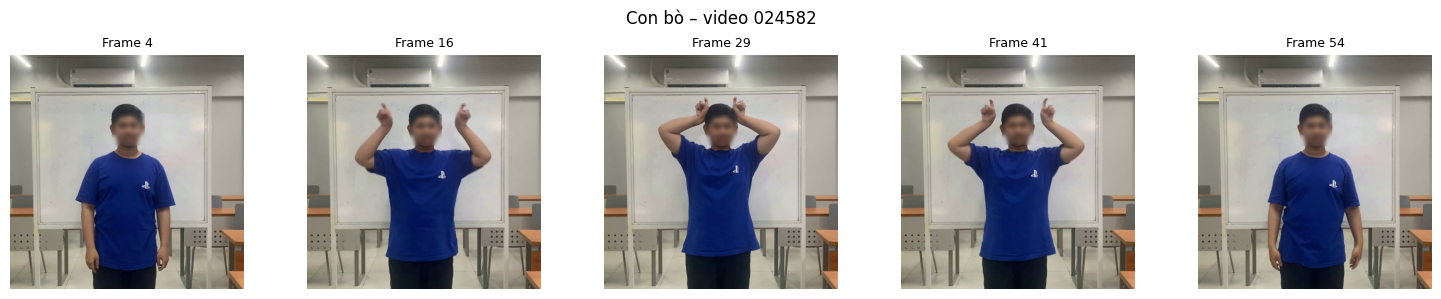

### Trường học · người ký `014` · video `010504` · 3.08s (25.00 FPS)

**Đã nhận đúng trong chuỗi một gloss của tập test.** Thời lượng video gốc 3.08s, khung ảnh gốc 77, keypoint 77 frame.

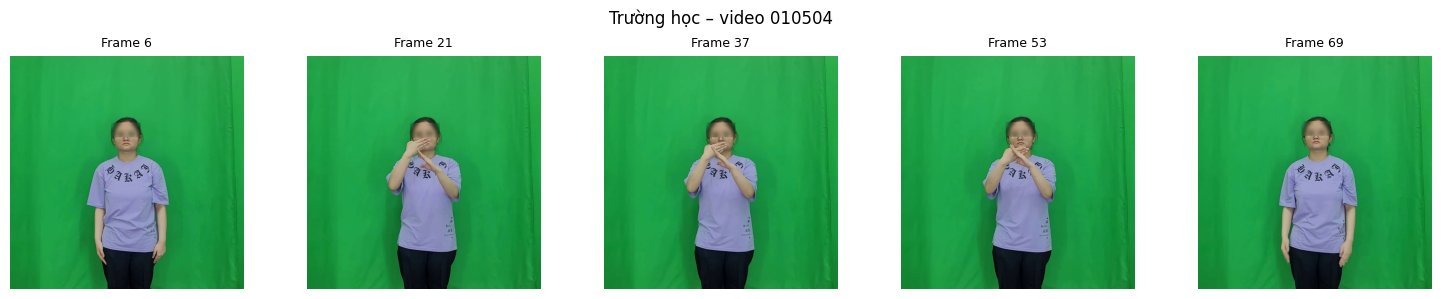

### Mưa · người ký `014` · video `010556` · 2.64s (25.00 FPS)

**Đã nhận đúng trong chuỗi một gloss của tập test.** Thời lượng video gốc 2.64s, khung ảnh gốc 66, keypoint 66 frame.

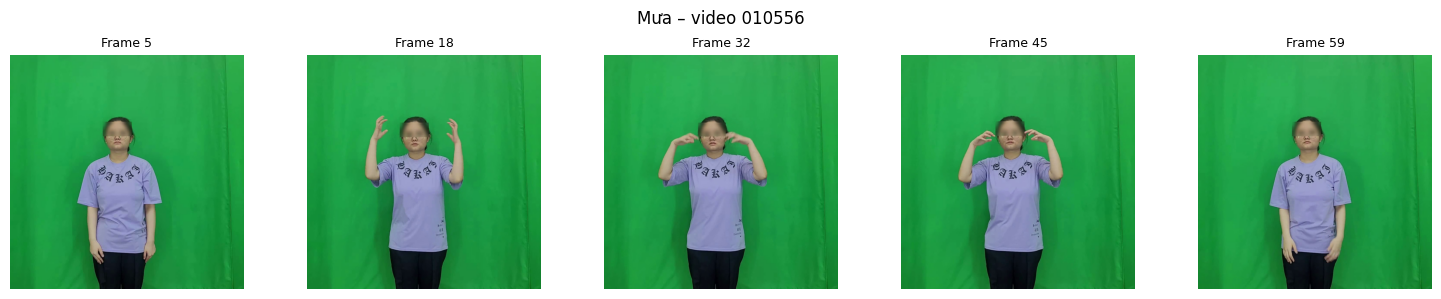

### Bố · người ký `001` · video `000715` · 1.88s (25.00 FPS)

**Đã nhận đúng trong chuỗi một gloss của tập test.** Thời lượng video gốc 1.88s, khung ảnh gốc 47, keypoint 47 frame.

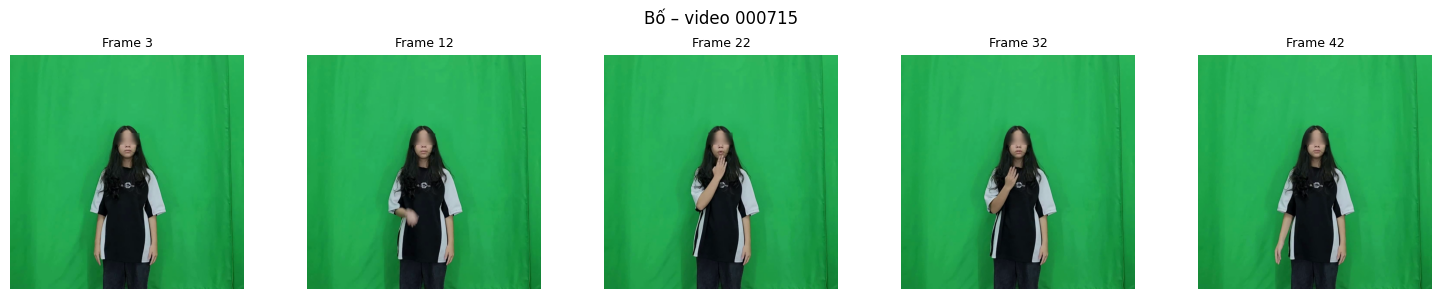

### Em · người ký `001` · video `000004` · 2.60s (25.00 FPS)

**Đã nhận đúng trong chuỗi một gloss của tập test.** Thời lượng video gốc 2.60s, khung ảnh gốc 65, keypoint 65 frame.

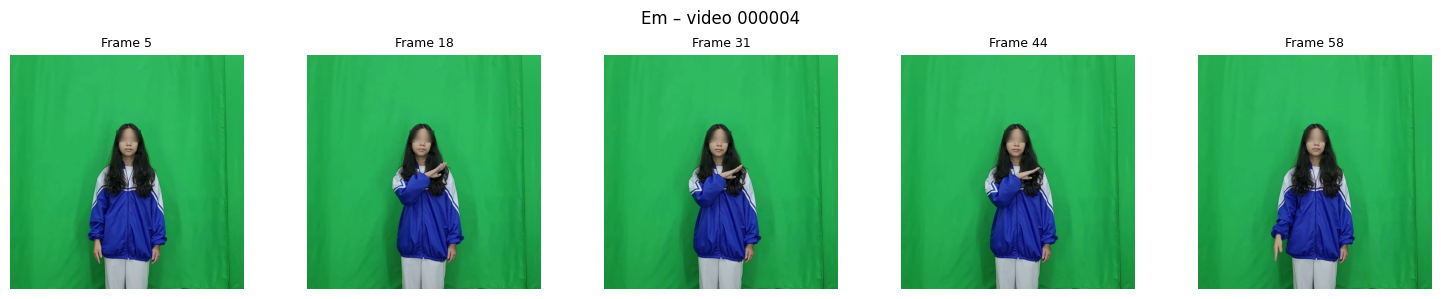

### Giúp đỡ · người ký `028` · video `024410` · 2.76s (25.00 FPS)

**Đã nhận đúng trong chuỗi một gloss của tập test.** Thời lượng video gốc 2.76s, khung ảnh gốc 69, keypoint 69 frame.

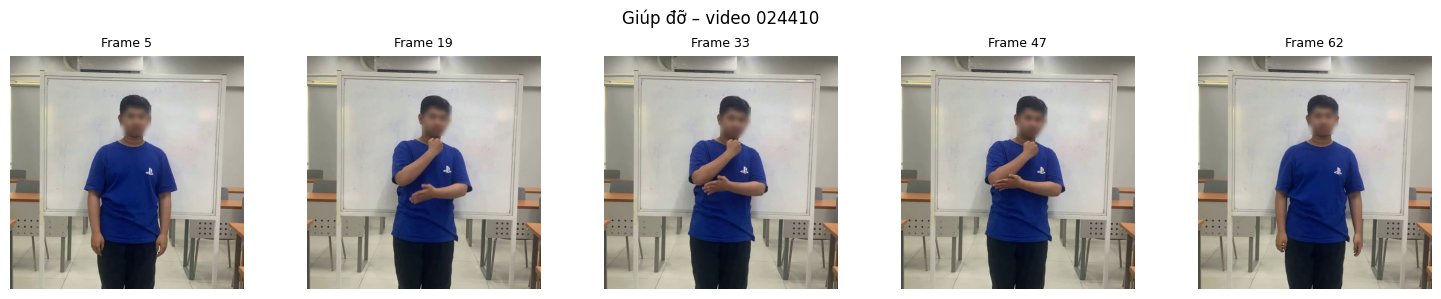

### Thời tiết · người ký `014` · video `010532` · 2.80s (25.00 FPS)

**Đã nhận đúng trong chuỗi một gloss của tập test.** Thời lượng video gốc 2.80s, khung ảnh gốc 70, keypoint 70 frame.

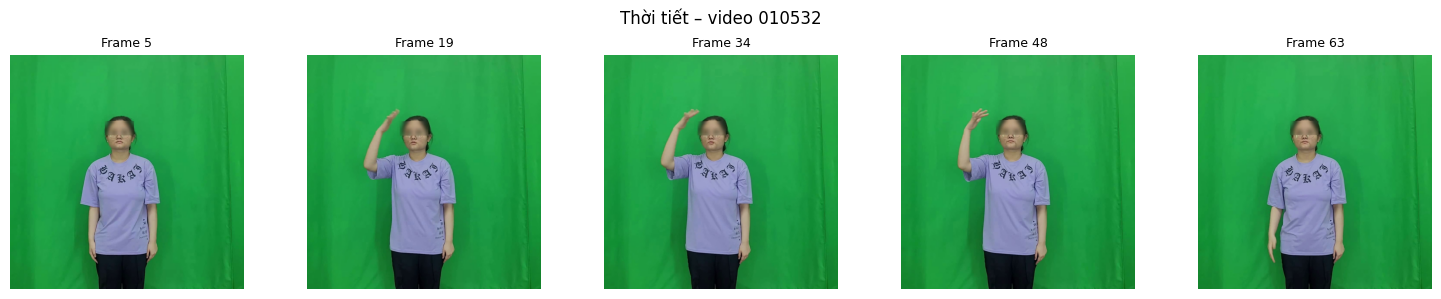

### Nhà trọ · người ký `001` · video `000096` · 2.84s (25.00 FPS)

**Đã nhận đúng trong chuỗi một gloss của tập test.** Thời lượng video gốc 2.84s, khung ảnh gốc 71, keypoint 71 frame.

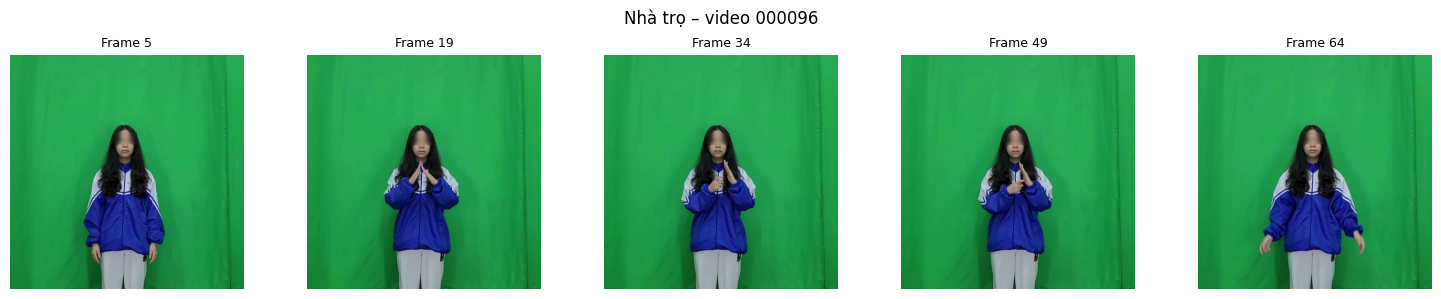

In [5]:
# 05 — PHÁT VIDEO NGƯỜI KÝ TRONG KAGGLE (tự chuyển mp4v sang H.264)
# Chỉ chuyển bản sao để xem; KHÔNG thay video gốc, keypoint, checkpoint, FPS hay kết quả nghiên cứu.
import shutil
import subprocess
from pathlib import Path
from IPython.display import Video, display, Markdown

if shutil.which('ffmpeg') is None:
    raise RuntimeError('Kaggle chưa có ffmpeg. Kiểm tra bằng !which ffmpeg trước khi chạy cell này.')

BROWSER_VIDEO_DIR = OUTPUT_DIR / 'video_h264_for_display'
BROWSER_VIDEO_DIR.mkdir(parents=True, exist_ok=True)

def browser_compatible_video(original_path, video_id):
    original_path = Path(original_path)
    if not original_path.is_file():
        raise FileNotFoundError(f'Không có video gốc: {original_path}')
    output = BROWSER_VIDEO_DIR / f'{video_id}_h264.mp4'
    if output.is_file() and output.stat().st_size > 1024:
        return output  # Sử dụng lại video đã chuyển ở lần chạy trước.

    command = [
        'ffmpeg', '-hide_banner', '-loglevel', 'error', '-y',
        '-i', str(original_path), '-map', '0:v:0', '-an',
        '-c:v', 'libx264', '-preset', 'veryfast', '-crf', '26',
        '-pix_fmt', 'yuv420p', '-vf', 'scale=640:-2',
        '-movflags', '+faststart', str(output)
    ]
    proc = subprocess.run(command, capture_output=True, text=True)
    if proc.returncode != 0 or not output.exists() or output.stat().st_size < 1024:
        raise RuntimeError(f'Chuyển video H.264 thất bại: {original_path.name}\n{proc.stderr[-1200:]}')
    return output

def storyboard(path, title='', count=5):
    cap = cv2.VideoCapture(str(path))
    total = max(1, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    indices = np.linspace(max(0,int(total*0.08)), max(0,int(total*0.92)-1), count).astype(int)
    frames=[]
    for ix in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(ix))
        ok, frame = cap.read()
        if ok:
            frames.append((ix,cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
    cap.release()
    if not frames:
        print('Không lấy được khung hình minh họa:', path)
        return
    fig, axes = plt.subplots(1, len(frames), figsize=(min(18, 3*len(frames)), 3))
    if len(frames)==1:
        axes=[axes]
    for ax,(frame_id,img) in zip(axes,frames):
        ax.imshow(img)
        ax.set_title(f'Frame {int(frame_id)}',fontsize=9)
        ax.axis('off')
    fig.suptitle(title,fontsize=12)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

for row in video_meta.itertuples(index=False):
    duration = ('không đọc được FPS' if row.duration_seconds is None or pd.isna(row.duration_seconds)
                else f'{row.duration_seconds:.2f}s')
    display(Markdown(f'### {row.gloss} · người ký `{row.signer_id}` · video `{row.video_id}` · {duration} ({row.fps:.2f} FPS)'))
    display(Markdown(f'**Đã nhận đúng trong chuỗi một gloss của tập {row.split}.** '
                     f'Thời lượng video gốc {duration}, khung ảnh gốc {row.video_frames}, '
                     f'keypoint {row.keypoint_frames} frame.'))
    if SHOW_INLINE_VIDEO:
        mp4 = browser_compatible_video(row.file_path, row.video_id)
        display(Video(data=mp4.read_bytes(), embed=True, mimetype='video/mp4', width=PLAY_WIDTH))
    if SHOW_STORYBOARD:
        storyboard(row.file_path, title=f'{row.gloss} – video {row.video_id}')


## 4. Thời lượng gợi ý để thử với webcam Mode A

Ưu tiên **ghi trọn động tác từ lúc chuẩn bị đến lúc kết thúc**; không kéo dài một ký hiệu thành nhiều giây bằng cách giữ tay bất động. Thời lượng gợi ý xuất phát từ FPS/khung hình **của clip gốc vừa đo**, cộng biên cho lúc bắt đầu và kết thúc (mỗi bên khoảng 0,2–0,4 giây). Đây là **mẹo vận hành**, không phải ngưỡng huấn luyện đã được chứng minh tối ưu. Nếu Mode A luôn lưu đủ 180 khung hình, thời lượng thực tế phụ thuộc FPS webcam (ví dụ 30 FPS là 6 giây), có thể dài hơn video mẫu; cần xem xét cắt đoạn động tác hay cơ chế kết thúc sớm trong ứng dụng.

**Bắt buộc:** sau khi sửa MediaPipe, kiểm tra **tỷ lệ landmark hai tay không bằng 0** trong lúc đang ký và CTC greedy có nhãn khác blank. Đừng đánh giá thành công chỉ bằng Top-1 fallback.

In [6]:
# 06 — Gợi ý số giây / số frame theo đúng FPS từ video, KHÔNG mặc định FPS
MIN_EXTRA=0.20;MAX_EXTRA=0.40
fps_webcam=30.0  # NHẬP FPS thực tế app quan sát được nếu biết; mặc định chỉ là ví dụ tính toán
plan=video_meta[['gloss','video_id','fps','duration_seconds','keypoint_frames']].copy()
plan['recommended_sec_min']=(plan.duration_seconds+2*MIN_EXTRA).round(2)
plan['recommended_sec_max']=(plan.duration_seconds+2*MAX_EXTRA).round(2)
plan['webcam_frames_est_min']=(plan.recommended_sec_min*fps_webcam).round().astype('Int64')
plan['webcam_frames_est_max']=(plan.recommended_sec_max*fps_webcam).round().astype('Int64')
plan.to_csv(OUTPUT_DIR/'recommended_capture_duration.csv',index=False,encoding='utf-8-sig')
display(plan)
print('180 frames ở webcam FPS=',fps_webcam,'là',round(180/fps_webcam,2),'giây. Đây là ví dụ, KHÔNG phải FPS đo được.')

,gloss,video_id,fps,duration_seconds,keypoint_frames,recommended_sec_min,recommended_sec_max,webcam_frames_est_min,webcam_frames_est_max
0,Con bò,024582,25.0,2.40,60,2.80,3.20,84,96
1,Trường học,010504,25.0,3.08,77,3.48,3.88,104,116
2,Mưa,010556,25.0,2.64,66,3.04,3.44,91,103
3,Bố,000715,25.0,1.88,47,2.28,2.68,68,80
4,Em,000004,25.0,2.60,65,3.00,3.40,90,102
5,Giúp đỡ,024410,25.0,2.76,69,3.16,3.56,95,107
6,Thời tiết,010532,25.0,2.80,70,3.20,3.60,96,108
7,Nhà trọ,000096,25.0,2.84,71,3.24,3.64,97,109


180 frames ở webcam FPS= 30.0 là 6.0 giây. Đây là ví dụ, KHÔNG phải FPS đo được.


## 5. (Tùy chọn) Xem clip tốc độ chậm nếu chuyển động khó quan sát

Nếu muốn xem chậm, dùng FFmpeg của Kaggle để tạo clip 0,75×. Chỉ chạy trên video bạn chọn; **không sửa FPS của dữ liệu đã dùng để huấn luyện hoặc đánh giá**, và không dùng video chậm để tính WER.

In [7]:
# 07 — Chạy riêng cell này nếu muốn video 0.75× (tạo bản xem, không làm đầu vào đánh giá)
MAKE_SLOW_VIDEO = False
if MAKE_SLOW_VIDEO:
    import subprocess
    for row in video_meta.head(4).itertuples(index=False):
        slow=OUTPUT_DIR/f'{row.video_id}_slow_0p75x.mp4'
        cmd=['ffmpeg','-y','-loglevel','error','-i',row.file_path,'-vf','setpts=1.333333*PTS',
             '-an','-c:v','libx264','-pix_fmt','yuv420p',str(slow)]
        subprocess.run(cmd,check=True)
        display(Markdown(f'Video chậm · **{row.gloss}**'))
        display(Video(data=slow.read_bytes(), embed=True, mimetype="video/mp4", width=PLAY_WIDTH))
else:
    print('Bỏ qua tạo video chậm (MAKE_SLOW_VIDEO=False).')

Bỏ qua tạo video chậm (MAKE_SLOW_VIDEO=False).


## 6. (Tùy chọn) Kiểm tra mô hình gốc bằng checkpoint trên keypoint đã lưu

Cell dưới chỉ thực hiện khi bạn gắn **cả** `VSL400_SHARED_KEYPOINTS_V1` và `VSL400_11_MULTISEED_TCN_TRANSFORMER` vào Kaggle. Khôi phục phép tính **đúng** của mô hình huấn luyện: TCN Conv1d không giãn (dilation=1), Transformer `activation='gelu'`, đầu vào `(T,42,7)` và blank 400. Suy luận lại các video từ keypoint gốc, tái tạo edge hold của recipe, so dự đoán CTC với nhãn. **Không** suy luận video raw bằng MediaPipe mới trong phần này; đó là kiểm thử *domain shift* riêng ở hệ thống webcam.

In [8]:
# 08 — Tìm các Saved Versions tùy chọn. Thiếu thì tự bỏ qua, notebook xem video vẫn chạy.
INPUT_DIR=Path('/kaggle/input')
def find_saved(name):
    found=[]
    for pat in [f'*/{name}',f'*/*/{name}',f'*/*/*/{name}']:
        found.extend(p for p in INPUT_DIR.glob(pat) if p.is_dir())
    roots=sorted({str(p.resolve()):p for p in found}.values(),key=str)
    return roots[0] if len(roots)==1 else None
shared_root=find_saved('VSL400_SHARED_KEYPOINTS_V1')
trained_root=find_saved('VSL400_11_MULTISEED_TCN_TRANSFORMER')
run_optional_inference=(shared_root is not None and trained_root is not None)
print('Keypoints:',shared_root)
print('Checkpoint:',trained_root)
print('Có thể thực hiện suy luận đối chứng:',run_optional_inference)

Keypoints: /kaggle/input/notebooks/nhttruong/vsl400-combine-5groups-shared-keypoints/VSL400_SHARED_KEYPOINTS_V1
Checkpoint: /kaggle/input/notebooks/nhttruong/vsl400-notebook-11-multi-seed-tcn-transformer-ct/VSL400_11_MULTISEED_TCN_TRANSFORMER
Có thể thực hiện suy luận đối chứng: True


In [9]:
# 09 — Chỉ khi đủ Saved Versions, nạp checkpoint chính thức (không train)
if run_optional_inference:
    import torch, torch.nn as nn, math
    DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    cp_path=trained_root/'checkpoints/best_seed_20260827.pt'
    assert cp_path.is_file(),f'Thiếu checkpoint: {cp_path}'
    ckpt=torch.load(cp_path,map_location='cpu',weights_only=True)
    assert ckpt['model_name']=='HandsTCNTransformerCTC' and int(ckpt['seed'])==20260827
    ARCH=ckpt['architecture']
    INPUT_DIM=294; MODEL_DIM=int(ARCH['model_dim']);
    TCN_LAYERS=int(ARCH['tcn_layers']); TCN_KERNEL_SIZE=int(ARCH['tcn_kernel_size'])
    TCN_DROPOUT=.2; TRANSFORMER_DROPOUT=.2
    NHEAD=int(ARCH['nhead']);TRANSFORMER_LAYERS=int(ARCH['transformer_layers']);FF_DIM=int(ARCH['ff_dim'])
    BLANK_BIAS_INIT=float(ARCH['blank_bias_init']); BLANK_ID=400; NUM_OUTPUTS=401; HAND_IDS=np.arange(34,76)
else:
    print('Chưa gắn đủ Saved Versions → bỏ qua các cell suy luận, vẫn xem video mẫu bình thường.')

In [10]:
# 10 — Architecture lấy theo mã nghiên cứu gốc, không dùng định nghĩa suy luận tự thay đổi
if run_optional_inference:
    # 7. Model definitions
    class SinusoidalPositionalEncoding(nn.Module):
        def __init__(self, dim, max_len=4096):
            super().__init__()

            pe = torch.zeros(max_len, dim)

            position = torch.arange(
                0, max_len, dtype=torch.float32
            ).unsqueeze(1)

            div_term = torch.exp(
                torch.arange(
                    0, dim, 2, dtype=torch.float32
                ) * (-math.log(10000.0) / dim)
            )

            pe[:,0::2] = torch.sin(position * div_term)
            pe[:,1::2] = torch.cos(position * div_term)

            self.register_buffer(
                "pe",
                pe.unsqueeze(0),
                persistent=False
            )

        def forward(self, x):
            return x + self.pe[:,:x.size(1)]

    class TemporalConvBlock(nn.Module):
        def __init__(self, dim, kernel_size=5, dropout=0.2):
            super().__init__()

            pad = kernel_size // 2

            self.net = nn.Sequential(
                nn.Conv1d(dim, dim, kernel_size, padding=pad),
                nn.BatchNorm1d(dim),
                nn.GELU(),
                nn.Dropout(dropout),

                nn.Conv1d(dim, dim, kernel_size, padding=pad),
                nn.BatchNorm1d(dim),
                nn.GELU(),
                nn.Dropout(dropout)
            )

            self.norm = nn.LayerNorm(dim)

        def forward(self, x):
            residual = x
            z = self.net(x.transpose(1,2)).transpose(1,2)
            return self.norm(residual + z)

    class HandsTCNTransformerCTC(nn.Module):
        def __init__(self):
            super().__init__()

            self.input_proj = nn.Sequential(
                nn.Linear(INPUT_DIM, MODEL_DIM),
                nn.LayerNorm(MODEL_DIM),
                nn.GELU(),
                nn.Dropout(0.15)
            )

            self.tcn = nn.ModuleList([
                TemporalConvBlock(
                    MODEL_DIM,
                    TCN_KERNEL_SIZE,
                    TCN_DROPOUT
                )
                for _ in range(TCN_LAYERS)
            ])

            self.pos = SinusoidalPositionalEncoding(
                MODEL_DIM
            )

            enc = nn.TransformerEncoderLayer(
                d_model=MODEL_DIM,
                nhead=NHEAD,
                dim_feedforward=FF_DIM,
                dropout=TRANSFORMER_DROPOUT,
                activation="gelu",
                batch_first=True,
                norm_first=True
            )

            self.transformer = nn.TransformerEncoder(
                enc,
                num_layers=TRANSFORMER_LAYERS,
                norm=nn.LayerNorm(MODEL_DIM)
            )

            self.classifier = nn.Linear(
                MODEL_DIM,
                NUM_OUTPUTS
            )

            with torch.no_grad():
                self.classifier.bias.zero_()
                self.classifier.bias[BLANK_ID] = BLANK_BIAS_INIT

        def forward(self, x, lengths):
            z = self.input_proj(x)

            for block in self.tcn:
                z = block(z)

            z = self.pos(z)

            T = z.shape[1]

            padding_mask = (
                torch.arange(
                    T,
                    device=z.device
                )[None,:]
                >= lengths[:,None].to(z.device)
            )

            z = self.transformer(
                z,
                src_key_padding_mask=padding_mask
            )

            return self.classifier(z)

In [11]:
# 11 — Kiểm tra lại từng clip và CTC greedy từ bộ NPZ thật
if run_optional_inference:
    model=HandsTCNTransformerCTC().to(DEVICE)
    model.load_state_dict(ckpt['state_dict'],strict=True)
    assert sum(p.numel() for p in model.parameters())==5442961
    model.eval()
    mf=pd.read_csv(shared_root/'manifest.csv',dtype={'video_id':str})
    mf['video_id']=mf.video_id.str.zfill(6)
    video_manifest=mf.set_index('video_id')
    label_map=json.loads((shared_root/'label_map.json').read_text(encoding='utf8'))['id_to_label']
    def one_gloss_features(row):
        r=video_manifest.loc[row.video_id]
        assert r['gloss']==row.gloss and int(r['label_id'])==int(row.label_id)
        with np.load(shared_root/str(r.npz_path),allow_pickle=False) as payload:
            xyz=np.asarray(payload['xyz'],dtype=np.float32)
            valid=np.asarray(payload['valid'],dtype=bool)
        assert xyz.shape[1:]==(108,3) and valid.shape==xyz.shape[:2]
        start=int(row.start_hold_frames);end=int(row.end_hold_frames)
        xyz=np.concatenate([np.repeat(xyz[:1],start,axis=0),xyz,np.repeat(xyz[-1:],end,axis=0)],axis=0)
        valid=np.concatenate([np.repeat(valid[:1],start,axis=0),valid,np.repeat(valid[-1:],end,axis=0)],axis=0)
        a=xyz[:,34:76];m=valid[:,34:76]
        vel=np.zeros_like(a)
        vel[1:]=a[1:]-a[:-1]
        vel[1:][~(m[1:]&m[:-1])]=0.0
        features=np.concatenate([a,vel,m[...,None].astype(np.float32)],axis=-1)
        assert features.shape==(int(row.expected_frames),42,7)
        return features.reshape(len(features),294)
    def greedy(ids):
        result=[];last=None
        for tok in ids:
            tok=int(tok)
            if tok!=400 and tok!=last:result.append(tok)
            last=tok
        return result
    results=[]
    for row in chosen.itertuples(index=False):
        feat=one_gloss_features(row)
        with torch.inference_mode():
            logits=model(torch.from_numpy(feat[None]).to(DEVICE),torch.tensor([len(feat)],device=DEVICE))[0]
            ids=logits.argmax(-1).cpu().tolist()
        pred_ids=greedy(ids)
        pred_gloss=' | '.join(label_map[str(i)] for i in pred_ids) if pred_ids else '<blank>'
        results.append({'gloss_ref':row.gloss,'video_id':row.video_id,'signer_id':row.signer_id,
                        'predicted_gloss':pred_gloss,'correct':pred_ids==[int(row.label_id)],
                        'blank_ratio':round(100*sum(i==400 for i in ids)/len(ids),2),
                        'frames_recipe':len(feat),'frames_raw':int(row.clip_frames_qa)})
    infer_df=pd.DataFrame(results)
    display(infer_df)
    infer_df.to_csv(OUTPUT_DIR/'optional_checkpoint_inference.csv',index=False,encoding='utf-8-sig')
    if not infer_df.correct.all():
        print('LƯU Ý: Kết quả suy luận khác với snapshot đã lưu; kiểm tra version artifact/trọng số và code theo ngày.')
else:
    print('Không suy luận checkpoint: chỉ xem video + thời lượng như yêu cầu.')

/tmp/ipykernel_16/2186484812.py:91: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


,gloss_ref,video_id,signer_id,predicted_gloss,correct,blank_ratio,frames_recipe,frames_raw
0,Con bò,024582,028,Con bò,True,98.55,69,60
1,Trường học,010504,014,Trường học,True,98.82,85,77
2,Mưa,010556,014,Mưa,True,98.63,73,66
3,Bố,000715,001,Bố,True,98.11,53,47
4,Em,000004,001,Em,True,98.59,71,65
5,Giúp đỡ,024410,028,Giúp đỡ,True,98.67,75,69
6,Thời tiết,010532,014,Thời tiết,True,98.70,77,70
7,Nhà trọ,000096,001,Nhà trọ,True,98.72,78,71


## 7. Ghi nhận kết quả kiểm thử webcam thực tế

Không ghi “đạt 100%” từ danh sách đã tuyển chọn. Để kiểm thử có thể kiểm chứng, dùng mỗi ký hiệu **3 lượt riêng**, Reset giữa các lượt, ghi: đúng/sai, FPS webcam, số frame thực tế, tỷ lệ phát hiện hai tay **qua toàn bộ lượt ghi**, predicted gloss và blank ratio. Nếu Top-5 cố định và tay không được phát hiện, **sửa pipeline** thay vì đổi gloss. Các bài test này nằm ngoài Test signer-disjoint chính thức và không dùng thay WER Chương 4.

In [12]:
# 12 — Bảng nhập kết quả thủ công từ webcam Mode A, xuất CSV làm minh chứng Chương 5
log_rows=[]
for gloss in TARGET_GLOSSES:
    for trial in range(1,4):
        log_rows.append({'gloss_tham_chieu':gloss,'lan_thu':trial,'thoi_luong_ghi_s':'',
            'fps_webcam':'','so_frame_ghi':'','ty_le_tay_trai_hop_le':'','ty_le_tay_phai_hop_le':'',
            'gloss_du_doan':'','dung_sai':'','blank_ratio':'','ghi_chu':''})
trial_log=pd.DataFrame(log_rows)
trial_path=OUTPUT_DIR/'webcam_test_blank_template.csv'
trial_log.to_csv(trial_path,index=False,encoding='utf-8-sig')
display(trial_log.head(12))
print('Mẫu ghi kết quả: ',trial_path)
print('Lưu ý: Tệp này đang để trống vì chưa có kết quả webcam thực nghiệm.')

,gloss_tham_chieu,lan_thu,thoi_luong_ghi_s,fps_webcam,so_frame_ghi,ty_le_tay_trai_hop_le,ty_le_tay_phai_hop_le,gloss_du_doan,dung_sai,blank_ratio,ghi_chu
0,Con bò,1,,,,,,,,,
1,Con bò,2,,,,,,,,,
2,Con bò,3,,,,,,,,,
3,Trường học,1,,,,,,,,,
4,Trường học,2,,,,,,,,,
5,Trường học,3,,,,,,,,,
6,Mưa,1,,,,,,,,,
7,Mưa,2,,,,,,,,,
8,Mưa,3,,,,,,,,,
9,Bố,1,,,,,,,,,


Mẫu ghi kết quả:  /kaggle/working/VSL400_SIGN_DEMO_REFERENCE/webcam_test_blank_template.csv
Lưu ý: Tệp này đang để trống vì chưa có kết quả webcam thực nghiệm.


## Nghiệm thu notebook

- Đã hiển thị video front-view người ký thực tế trong cell 05 (không phải video mô phỏng).
- Đã tính FPS và thời lượng từ metadata video thật trong cell 04.
- Có ít nhất một video per gloss với `exact_match=True` trong các phép thử 1 gloss đã được lưu.
- Kết quả demo không được quảng bá là chính xác tuyệt đối trên webcam.
- Nếu kích hoạt cell 11, phải giữ mô hình đúng kiến trúc và checkpoint 20260827, không train và không điều chỉnh để đạt gloss mong muốn.